# Freight Rate Prediction — Exploratory Data Analysis & Modeling Pipeline
**Spotter ML Assessment**  
**Author:** Naveen Mishra  
**Environment:** Miniconda `ml` (Python 3.12, LightGBM, XGBoost, Scikit-Learn)

---

### Executive Summary & Objective
This notebook demonstrates an end-to-end machine learning solution for predicting freight load rates:
1. **Development Data:** 48,000 labeled loads spanning January 1, 2025 to October 31, 2025 (`data/train-test.csv`).
2. **Target Variable:** Total posted load rate in USD (`posted_rate`).
3. **Prediction Task:** Generate rate predictions for 12,000 future loads spanning November 1, 2025 to December 31, 2025 (`data/validation.csv`).
4. **Lane Forecasting Task:** Forecast rates across all 31 days of December 2025 for a fixed lane (Lexington $\rightarrow$ Fort Wayne, 360 miles, Dry Van, 32,000 lb).
5. **Contract Compliance:** Fully validated by the supplied `score.py` format and constraint verification suite.

## 1. Setup & Environment Configuration

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.stats as stats

warnings.filterwarnings("ignore")

# Configure plot styling
plt.rcParams.update({
    "figure.titlesize": 14,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#9DAFB3",
    "grid.color": "#E5ECEE",
    "grid.linestyle": "--",
    "grid.alpha": 0.7,
})

ROOT = Path("..").resolve() if Path("..").resolve().name == "Spotter" else Path(".").resolve()
DATA_DIR = ROOT / "data"
ARTIFACTS_DIR = ROOT / "artifacts"
print(f"Project Root: {ROOT}")
print(f"Data Directory: {DATA_DIR}")
print(f"Artifacts Directory: {ARTIFACTS_DIR}")

Project Root: /home/mveen/Desktop/Spotter
Data Directory: /home/mveen/Desktop/Spotter/data
Artifacts Directory: /home/mveen/Desktop/Spotter/artifacts


## 2. Data Ingestion & Schema Audit

In [2]:
from freight.data import read_inputs

frames, paths = read_inputs(ROOT)
train = frames['train']
val = frames['validation']
template = frames['template']
december = frames['december']

print(f"Training set:   {len(train):,} rows | {train.shape[1]} columns | {train['date'].min().date()} to {train['date'].max().date()}")
print(f"Validation set: {len(val):,} rows | {val.shape[1]} columns | {val['date'].min().date()} to {val['date'].max().date()}")
print(f"Template set:   {len(template):,} rows | columns: {list(template.columns)}")
print(f"December inputs:{len(december):,} rows | {december['date'].min()} to {december['date'].max()}")

assert len(train) == 48000, "Expected 48,000 training rows"
assert len(val) == 12000, "Expected 12,000 validation rows"
assert len(template) == 12000, "Expected 12,000 template rows"
assert set(val['load_id']) == set(template['load_id']), "Validation IDs must match template exactly"
assert train['date'].max() < val['date'].min(), "Strict temporal separation required (train before validation)"
print("\nAll schema and row integrity assertions passed!")

Training set:   48,000 rows | 14 columns | 2025-01-01 to 2025-10-31
Validation set: 12,000 rows | 13 columns | 2025-11-01 to 2025-12-31
Template set:   12,000 rows | columns: ['load_id', 'predicted_rate']
December inputs:31 rows | 2025-12-01 to 2025-12-31

All schema and row integrity assertions passed!


## 3. Data Quality Issues Identified & Cleaning Decisions

Our audit of the raw data uncovered several critical data-quality anomalies:
1. **Missing & Nonpositive Weights:**
   - Training contains **300 missing** weights and **292 nonpositive** weights (e.g. 0 or negative values).
   - Validation contains **165 missing** weights and **145 nonpositive** weights.
   - *Cleaning Decision:* We explicitly treat nonpositive weights as missing values and generate binary indicator flags (`weight_missing`, `weight_invalid`). We deliberately do NOT reverse the sign (taking `abs(weight)`), as nonpositive weights are data-entry errors, not mirrored values. Imputation is done using the historical median fitted strictly within each training fold.
2. **Missing Market Indices:**
   - Training contains **374 missing** market indices; validation contains **249 missing** market indices.
   - *Cleaning Decision:* Imputed with the fold-level historical median, flagged with `market_index_missing`.
3. **Extreme Target Values (Heavy Tail):**
   - Development rates range from **\$57.22 to \$25,533.00** with a mean of \$2,384.81 and median of \$1,848.33.
   - All targets are positive and finite; no nonpositive rates exist.
   - *Modeling Decision:* We do not trim or winsorize high rates, as they represent genuine expensive specialty/long-haul loads. However, because squared-error (L2) loss is heavily distorted by the upper 1% tail, we incorporate robust absolute-loss (L1 / MAE) objectives.

In [3]:
# Inspect data quality summary
train_nulls = train.isna().sum()
val_nulls = val.isna().sum()
quality_df = pd.DataFrame({
    "Train Missing": train_nulls,
    "Train <= 0": [int((pd.to_numeric(train[col], errors='coerce') <= 0).sum()) if col in ['distance', 'weight', 'market_index', 'quote_signal', 'posted_rate'] else 0 for col in train.columns],
    "Val Missing": [val_nulls.get(col, 0) for col in train.columns],
    "Val <= 0": [int((pd.to_numeric(val[col], errors='coerce') <= 0).sum()) if col in val.columns and col in ['distance', 'weight', 'market_index', 'quote_signal'] else 0 for col in train.columns],
}, index=train.columns)
print("Data Quality & Null Counts:")
print(quality_df[quality_df.sum(axis=1) > 0])

Data Quality & Null Counts:
              Train Missing  Train <= 0  Val Missing  Val <= 0
weight                  300         292          165       145
market_index            374           0          249         0


## 4. Exploratory Data Analysis & Visualizations

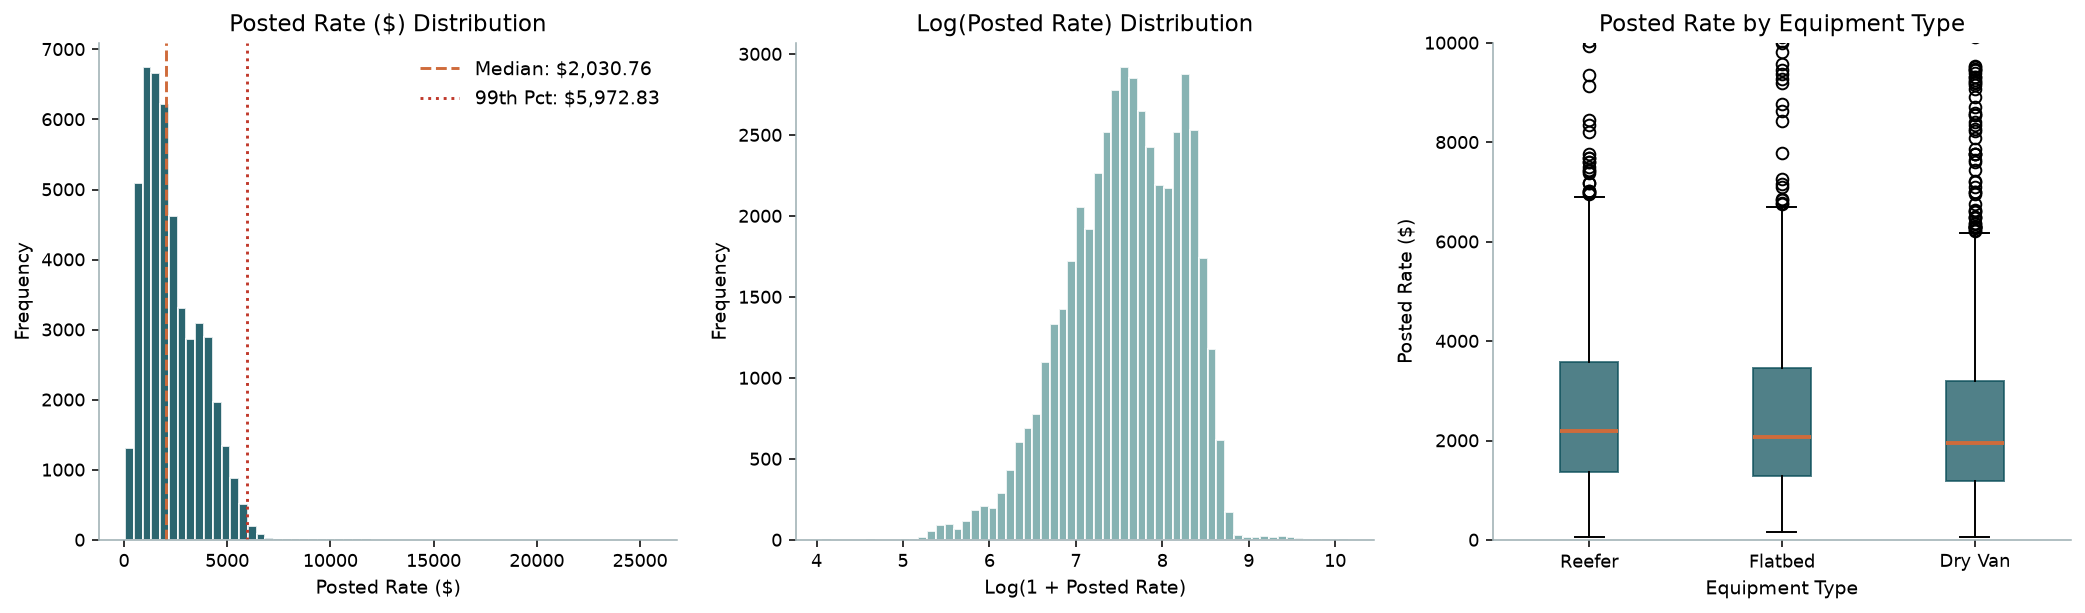

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Target distribution
axes[0].hist(train['posted_rate'], bins=60, color='#064A56', edgecolor='white', alpha=0.85)
axes[0].set_title("Posted Rate ($) Distribution")
axes[0].set_xlabel("Posted Rate ($)")
axes[0].set_ylabel("Frequency")
axes[0].axvline(train['posted_rate'].median(), color='#CF6B3B', linestyle='--', label=f"Median: ${train['posted_rate'].median():,.2f}")
axes[0].axvline(train['posted_rate'].quantile(0.99), color='#C0392B', linestyle=':', label=f"99th Pct: ${train['posted_rate'].quantile(0.99):,.2f}")
axes[0].legend(frameon=False)

# Log Target distribution
axes[1].hist(np.log1p(train['posted_rate']), bins=60, color='#72A6A6', edgecolor='white', alpha=0.85)
axes[1].set_title("Log(Posted Rate) Distribution")
axes[1].set_xlabel("Log(1 + Posted Rate)")
axes[1].set_ylabel("Frequency")

# Rate by Equipment
equipment_order = train.groupby('equipment')['posted_rate'].median().sort_values(ascending=False).index
data_by_eq = [train[train['equipment'] == eq]['posted_rate'] for eq in equipment_order]
axes[2].boxplot(data_by_eq, tick_labels=equipment_order, patch_artist=True,
                boxprops=dict(facecolor='#064A56', color='#064A56', alpha=0.7),
                medianprops=dict(color='#CF6B3B', linewidth=2))
axes[2].set_title("Posted Rate by Equipment Type")
axes[2].set_xlabel("Equipment Type")
axes[2].set_ylabel("Posted Rate ($)")
axes[2].set_ylim(0, 10000)

plt.tight_layout()
plt.show()

Quote Baseline Diagnostic across entire development set:
  Median Absolute Error: $55.55
  Mean Absolute Error:   $232.26
  Root Mean Squared Err: $674.57


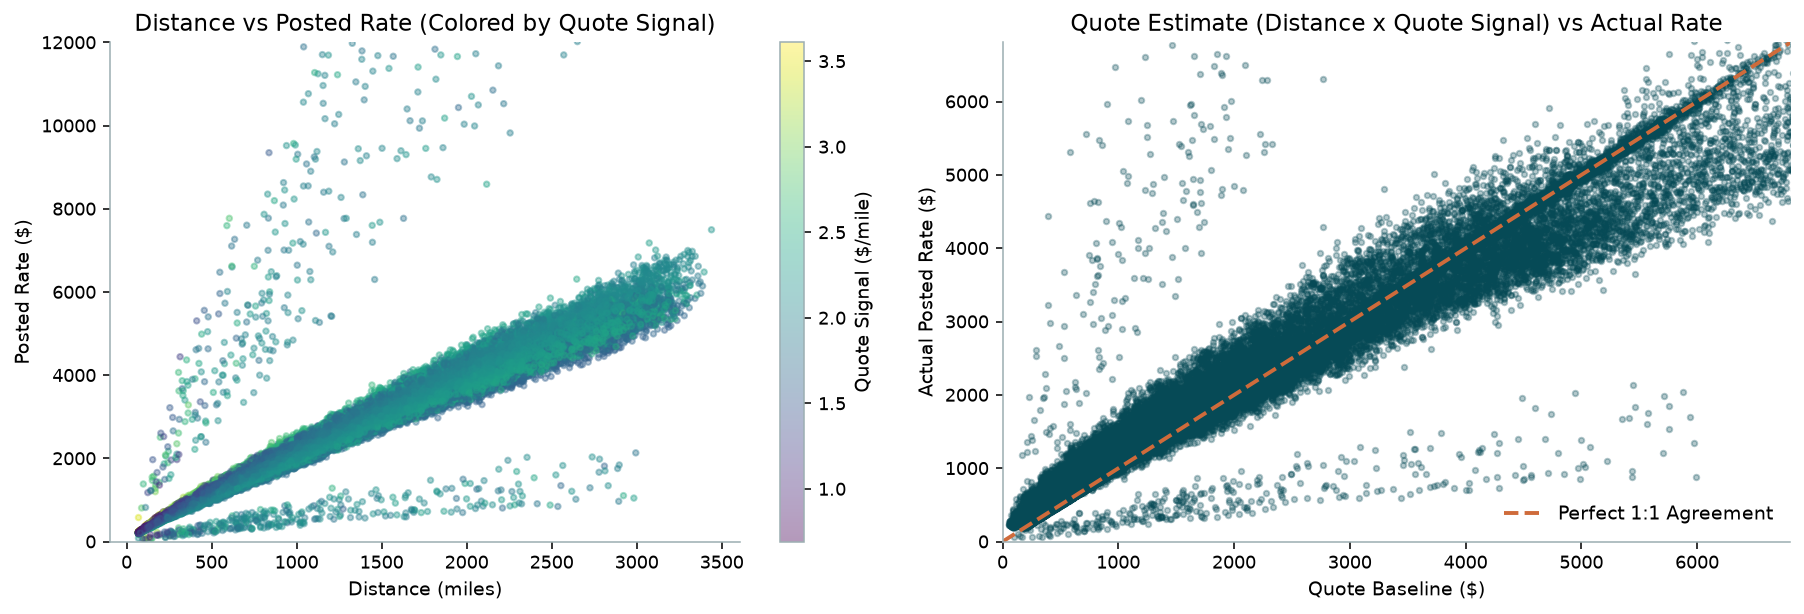

In [5]:
# Distance vs Posted Rate & Quote Signal Relationship
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Distance vs Posted Rate
scatter = axes[0].scatter(train['distance'], train['posted_rate'], c=train['quote_signal'],
                          cmap='viridis', alpha=0.4, s=8)
fig.colorbar(scatter, ax=axes[0], label='Quote Signal ($/mile)')
axes[0].set_title("Distance vs Posted Rate (Colored by Quote Signal)")
axes[0].set_xlabel("Distance (miles)")
axes[0].set_ylabel("Posted Rate ($)")
axes[0].set_ylim(0, 12000)

# Quote Signal * Distance vs Actual Posted Rate
quote_estimate = train['distance'] * train['quote_signal']
axes[1].scatter(quote_estimate, train['posted_rate'], alpha=0.3, s=8, color='#064A56')
lim = max(quote_estimate.quantile(0.995), train['posted_rate'].quantile(0.995))
axes[1].plot([0, lim], [0, lim], color='#CF6B3B', linestyle='--', linewidth=2, label='Perfect 1:1 Agreement')
axes[1].set_title("Quote Estimate (Distance x Quote Signal) vs Actual Rate")
axes[1].set_xlabel("Quote Baseline ($)")
axes[1].set_ylabel("Actual Posted Rate ($)")
axes[1].set_xlim(0, lim)
axes[1].set_ylim(0, lim)
axes[1].legend(frameon=False)

plt.tight_layout()
plt.show()

# Quantitative baseline diagnostic
quote_err = (train['posted_rate'] - quote_estimate).abs()
print(f"Quote Baseline Diagnostic across entire development set:")
print(f"  Median Absolute Error: ${quote_err.median():.2f}")
print(f"  Mean Absolute Error:   ${quote_err.mean():.2f}")
print(f"  Root Mean Squared Err: ${np.sqrt((quote_err**2).mean()):.2f}")

## 5. Geographic & Distribution Shift Analysis
A crucial finding in our audit is the presence of **geographic distribution shift**:
- **8 Unseen Prediction Cities:** Allentown, Charlotte, Chicago, Jackson, Knoxville, Laredo, Norfolk, and San Diego appear in `validation.csv` but never in `train-test.csv`.
- **1,461 Unseen Routes:** Over 12% of the validation loads run on pickup-delivery pairs that never appeared in development.
- **Coordinate Consistency:** In the training data, every named city maps to exactly one unique `(lat, lon)` pair. However, comparing these coordinates against standard geographic databases reveals that they are synthetic/dataset-specific. Therefore, external geocoding must NOT be used.

In [6]:
train_cities = set(train['pickup']) | set(train['delivery'])
val_cities = set(val['pickup']) | set(val['delivery'])
unseen_cities = sorted(val_cities - train_cities)

train_routes = set(zip(train['pickup'], train['delivery']))
val_routes = list(zip(val['pickup'], val['delivery']))
unseen_route_count = sum(r not in train_routes for r in val_routes)

print(f"Training cities count:   {len(train_cities)}")
print(f"Validation cities count: {len(val_cities)}")
print(f"Unseen cities in validation ({len(unseen_cities)}): {', '.join(unseen_cities)}")
print(f"Unseen route rows in validation: {unseen_route_count:,} / {len(val):,} ({unseen_route_count/len(val):.1%})")

Training cities count:   64
Validation cities count: 72
Unseen cities in validation (8): Allentown, Charlotte, Chicago, Jackson, Knoxville, Laredo, Norfolk, San Diego
Unseen route rows in validation: 1,461 / 12,000 (12.2%)


## 6. Feature Engineering Architecture

To capture physical freight dynamics and seasonal rate variations without data leakage, we engineer domain-tailored features:
1. **Distance Transforms:** `log_distance`, `sqrt_distance`, `inverse_distance` to capture non-linear rate-per-mile tapering over longer hauls.
2. **Payload Density:** `weight_per_mile = weight / distance`.
3. **Haversine Geometry:** `geo_miles` computed from spherical trigonometry and `road_geo_ratio = distance / geo_miles` (circuitous vs direct routes).
4. **Fourier Calendar Harmonics:** Annual (365.25-day) and weekly (7-day) Fourier sine/cosine bases with harmonics $k \in \{1, 2\}$. This provides smooth periodic extrapolation into December without memorizing unobserved months.
5. **Dual Pipeline Modes (Enriched vs Core):**
   - **Enriched Mode:** Uses `quote_signal`, `quote_total = quote_signal * distance`, `market_distance`, `quote_market_ratio`. Used for `validation.csv`.
   - **Core Mode:** Strictly ignores all quote and coordinate columns, deriving coordinates only from the fitted historical city map. Used for the December forecast where privileged market fields are absent.

In [7]:
from freight.features import Features

feat_builder = Features(mode='enriched').fit(train)
sample_features = feat_builder.transform(train.head(5))

print(f"Total engineered features: {sample_features.shape[1]}")
print(f"Engineered columns sample:\n{list(sample_features.columns)}")

Total engineered features: 47
Engineered columns sample:
['pickup', 'delivery', 'equipment', 'route', 'distance_missing', 'distance_invalid', 'distance', 'weight_missing', 'weight_invalid', 'weight', 'market_index_missing', 'market_index_invalid', 'market_index', 'quote_signal_missing', 'quote_signal_invalid', 'quote_signal', 'pickup_lat_missing', 'pickup_lat', 'pickup_lon_missing', 'pickup_lon', 'delivery_lat_missing', 'delivery_lat', 'delivery_lon_missing', 'delivery_lon', 'log_distance', 'inverse_distance', 'sqrt_distance', 'weight_per_mile', 'lat_delta', 'lon_delta', 'geo_miles', 'road_geo_ratio', 'weekday', 'weekend', 'month_start', 'month_end', 'calendar_365.25_1_sin', 'calendar_365.25_1_cos', 'calendar_365.25_2_sin', 'calendar_365.25_2_cos', 'calendar_7_1_sin', 'calendar_7_1_cos', 'calendar_7_2_sin', 'calendar_7_2_cos', 'quote_total', 'market_distance', 'quote_market_ratio']


## 7. Chronological Validation Strategy & Leakage Prevention

Standard random $K$-fold cross-validation is fatally flawed for time-series forecasting because it trains on future observations to predict past ones, causing severe optimistic bias and lookahead leakage.

We establish a **strict chronological backtesting architecture**:
- **Tuning Fold 1:** Train Jan 1 – Apr 30 $\rightarrow$ Validate May 1 – Jun 30 (9,696 loads).
- **Tuning Fold 2:** Train Jan 1 – Jun 30 $\rightarrow$ Validate Jul 1 – Aug 31 (9,671 loads).
- **Inner Early Stopping:** Boosting iteration counts are determined on the final month *inside* the training history (e.g. April for Fold 1, June for Fold 2), completely insulating the outer validation labels from tuning.
- **Locked Holdout:** Train Jan 1 – Aug 31 $\rightarrow$ Evaluate Sep 1 – Oct 31 (9,523 loads). Evaluated exactly once on the pre-selected configuration; never used for tuning.
- **All-History Fit:** Train Jan 1 – Oct 31 (48,000 loads) $\rightarrow$ Predict Nov 1 – Dec 31 (12,000 loads).

In [8]:
# Load saved tuning metrics from the experimental comparison
tuning_metrics = pd.read_csv(ARTIFACTS_DIR / "tuning_metrics.csv")
tuning_summary = tuning_metrics.groupby(['mode', 'model'])[['rmse', 'mae', 'wape_percent', 'r2']].mean().reset_index()
tuning_summary = tuning_summary.sort_values(['mode', 'rmse'])

print("Cross-Validation Model Comparison (Mean across Tuning Folds):")
print(tuning_summary.to_string(index=False))

Cross-Validation Model Comparison (Mean across Tuning Folds):
    mode            model       rmse        mae  wape_percent       r2
    core           lgb_l1 639.439091 156.514637      6.463726 0.822792
    core           xgb_l2 646.086969 173.141024      7.164855 0.819011
    core           lgb_l2 647.965248 170.618842      7.051564 0.817969
    core         lgb_rate 658.364799 180.709584      7.465536 0.811987
    core        equipment 658.527509 214.457752      8.876975 0.811718
    core       ridge_rate 668.580524 231.326228      9.639330 0.805059
enriched           lgb_l1 643.011207 145.812942      6.019057 0.820802
enriched        equipment 658.527509 214.457752      8.876975 0.811718
enriched           xgb_l2 660.978218 197.455925      8.132065 0.810674
enriched           lgb_l2 663.279503 200.071334      8.239350 0.809355
enriched       ridge_rate 665.655679 228.215913      9.507970 0.806880
enriched calibrated_quote 704.626177 272.874326     11.308696 0.784290
enriched     lg

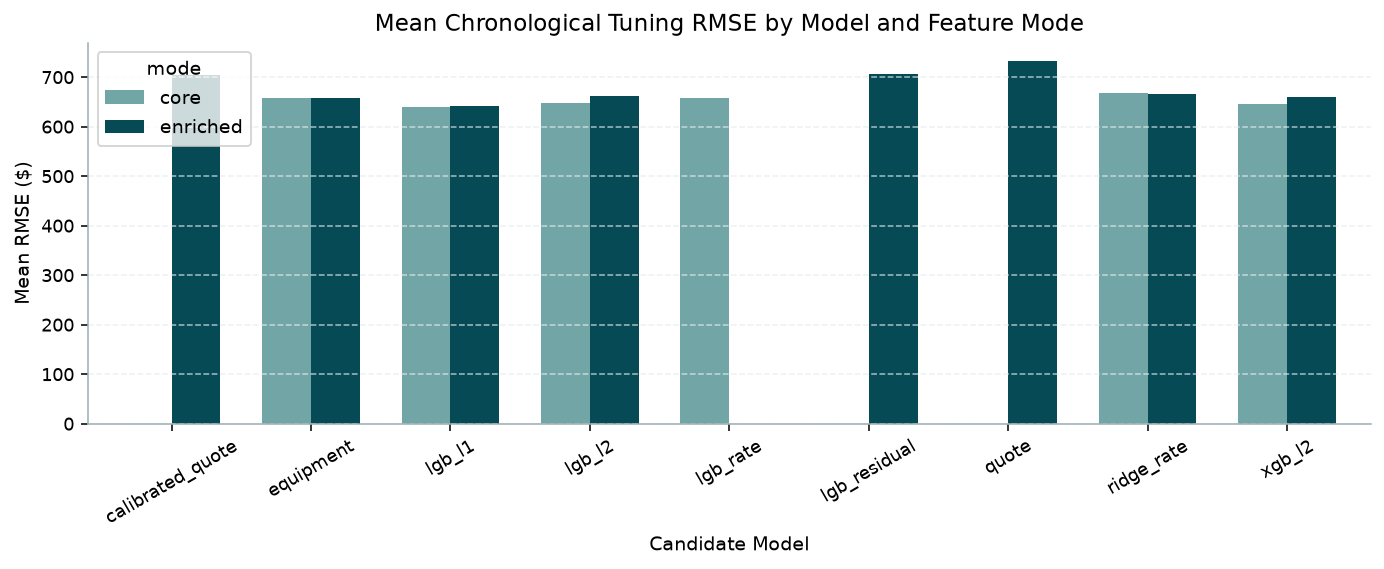

In [9]:
# Plot tuning RMSE across candidates
fig, ax = plt.subplots(figsize=(10, 4.2))
pivot_rmse = tuning_metrics.groupby(['mode', 'model'])['rmse'].mean().unstack(0)
pivot_rmse.plot.bar(ax=ax, color=['#72A6A6', '#064A56'], width=0.7)
ax.set_title("Mean Chronological Tuning RMSE by Model and Feature Mode")
ax.set_ylabel("Mean RMSE ($)")
ax.set_xlabel("Candidate Model")
ax.tick_params(axis='x', rotation=30)
ax.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## 8. Model Selection & Locked Holdout Evaluation

Across both the Enriched and Core paths, the convex blend grid identified:
**75% LightGBM L1 (Absolute Loss) + 25% Equipment-specific Median RPM Baseline**  
as the optimal model under the declared mean fold RMSE criterion.

### Why this combination succeeded:
- **LightGBM L1** optimizes absolute error, which prevents the severe over-fitting that squared-error models experience when trying to minimize residuals on the extreme 1% upper tail ($20,000+ loads).
- **Equipment RPM Baseline** anchors the predictions with physical lane economics ($/mile per trailer type), providing exceptional stability for unseen routes and rare locations.

Locked Holdout Evaluation (Sep 1 – Oct 31, 9,523 Loads):
                      rmse         mae  wape_percent        r2       bias
enriched        633.769732  119.415737      4.991357  0.827526 -67.117425
core            631.038291  113.772053      4.755462  0.829009 -27.550212
quote_baseline  711.799751  246.021653     10.283251  0.782441 -42.309286


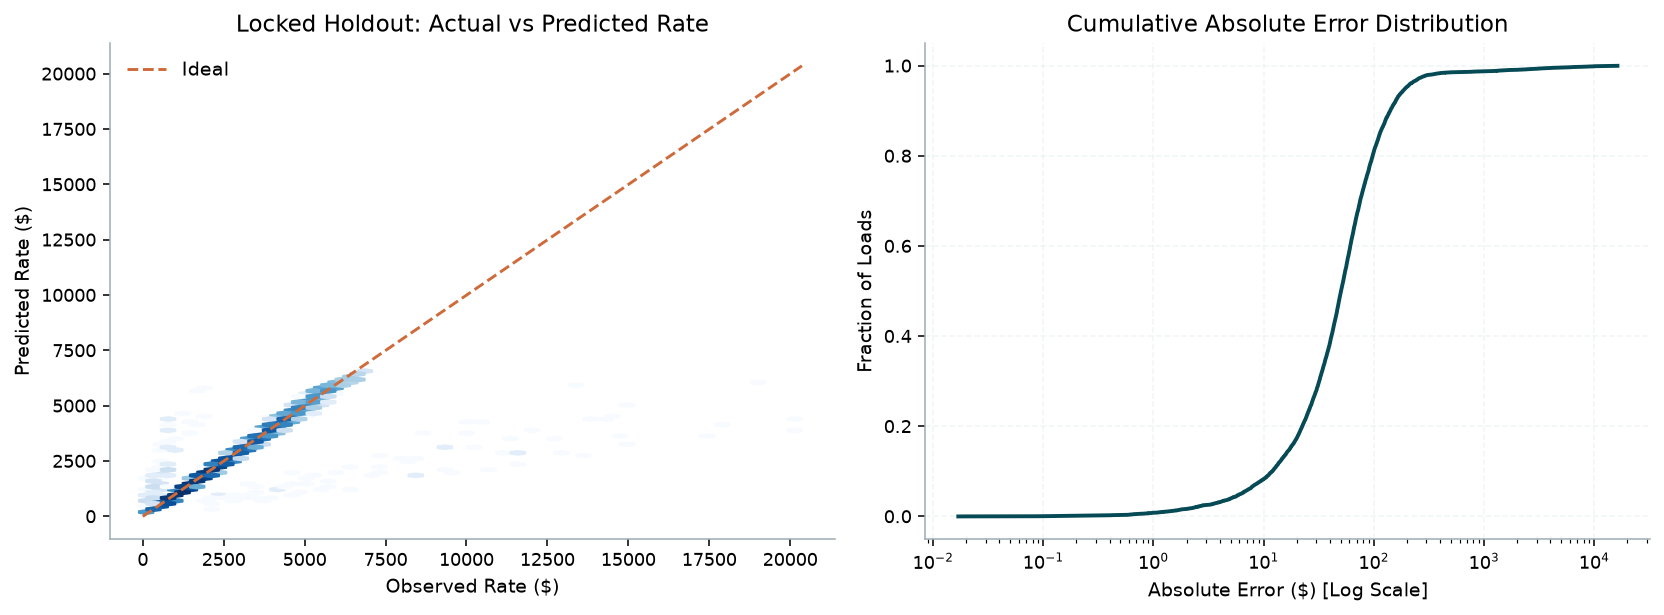

In [10]:
# Load locked holdout evaluation
with open(ARTIFACTS_DIR / "locked_holdout_metrics.json") as f:
    holdout_metrics = json.load(f)

holdout_table = pd.DataFrame(holdout_metrics).T
print("Locked Holdout Evaluation (Sep 1 – Oct 31, 9,523 Loads):")
print(holdout_table[['rmse', 'mae', 'wape_percent', 'r2', 'bias']])

# Load holdout predictions and plot error diagnostics
holdout_preds = pd.read_csv(ARTIFACTS_DIR / "locked_holdout_predictions.csv")
y_true = holdout_preds['posted_rate']
y_pred = holdout_preds['enriched_prediction']

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Hexbin plot of predictions
axes[0].hexbin(y_true, y_pred, gridsize=45, bins='log', cmap='Blues', mincnt=1)
lim = max(float(y_true.max()), float(y_pred.max()))
axes[0].plot([0, lim], [0, lim], '--', color='#CF6B3B', linewidth=1.5, label='Ideal')
axes[0].set_title("Locked Holdout: Actual vs Predicted Rate")
axes[0].set_xlabel("Observed Rate ($)")
axes[0].set_ylabel("Predicted Rate ($)")
axes[0].legend(frameon=False)

# Cumulative absolute error curve
errors = np.sort(np.abs(y_true - y_pred))
axes[1].plot(errors, np.arange(1, len(errors) + 1) / len(errors), color='#064A56', linewidth=2)
axes[1].set_title("Cumulative Absolute Error Distribution")
axes[1].set_xlabel("Absolute Error ($) [Log Scale]")
axes[1].set_ylabel("Fraction of Loads")
axes[1].set_xscale("log")
axes[1].grid(True, alpha=0.5)

plt.tight_layout()
plt.show()

## 9. Feature Importance Analysis

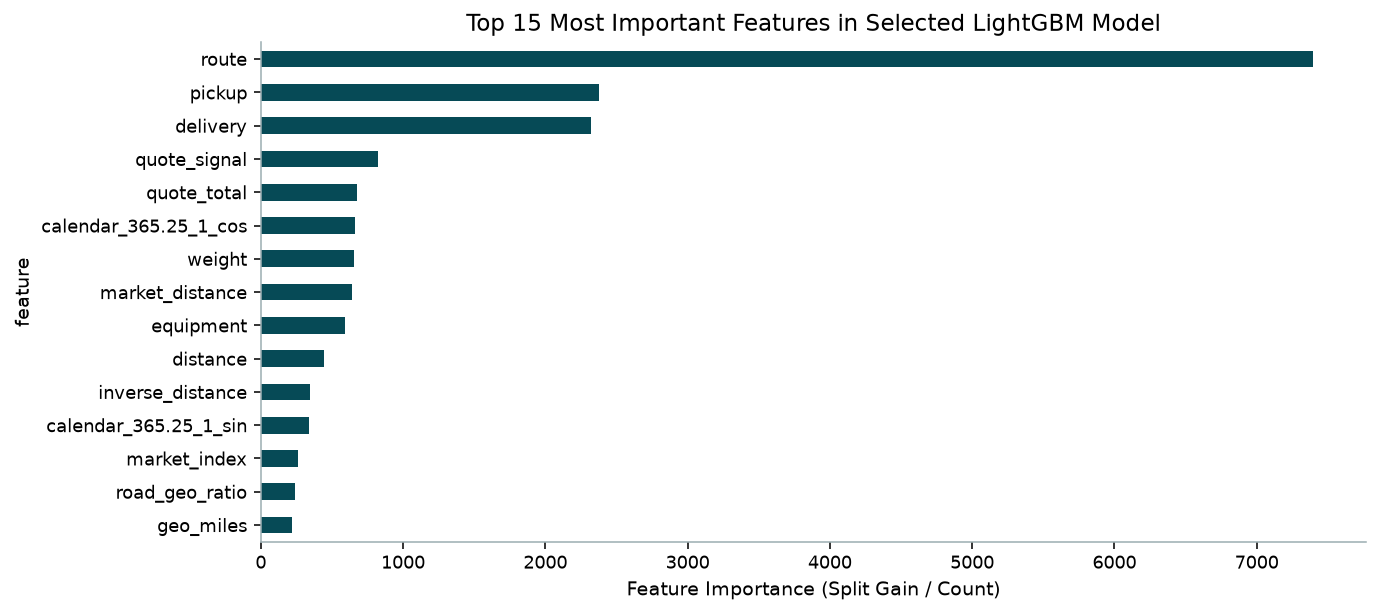

In [11]:
with open(ARTIFACTS_DIR / "enriched_feature_importance.json") as f:
    feat_imp = json.load(f)

imp_df = pd.DataFrame(feat_imp)
if not imp_df.empty:
    top_feats = imp_df.groupby("feature")["importance"].mean().sort_values(ascending=False).head(15)
    fig, ax = plt.subplots(figsize=(10, 4.5))
    top_feats.sort_values().plot.barh(ax=ax, color='#064A56')
    ax.set_title("Top 15 Most Important Features in Selected LightGBM Model")
    ax.set_xlabel("Feature Importance (Split Gain / Count)")
    plt.tight_layout()
    plt.show()

## 10. December 2025 Fixed Lane Forecast & Official Scorer Verification

For the required December forecast:
- Fixed parameters: Lexington $\rightarrow$ Fort Wayne, 360 miles, Dry Van, 32,000 lb.
- Rate varies across all 31 days of December 2025.
- Because December input omits quote signal and market index, predictions are generated using the separately trained and validated **Core Model**.
- We execute the provided `score.py` to verify output contracts and generate the candidate December chart.

score.py output:
Validated 12,000 final predictions.
Validated 31 fixed December predictions.
Created chart: /home/mveen/Desktop/Spotter/scorer_results/candidate_december.png
Final validation metrics are calculated by Spotter after submission.


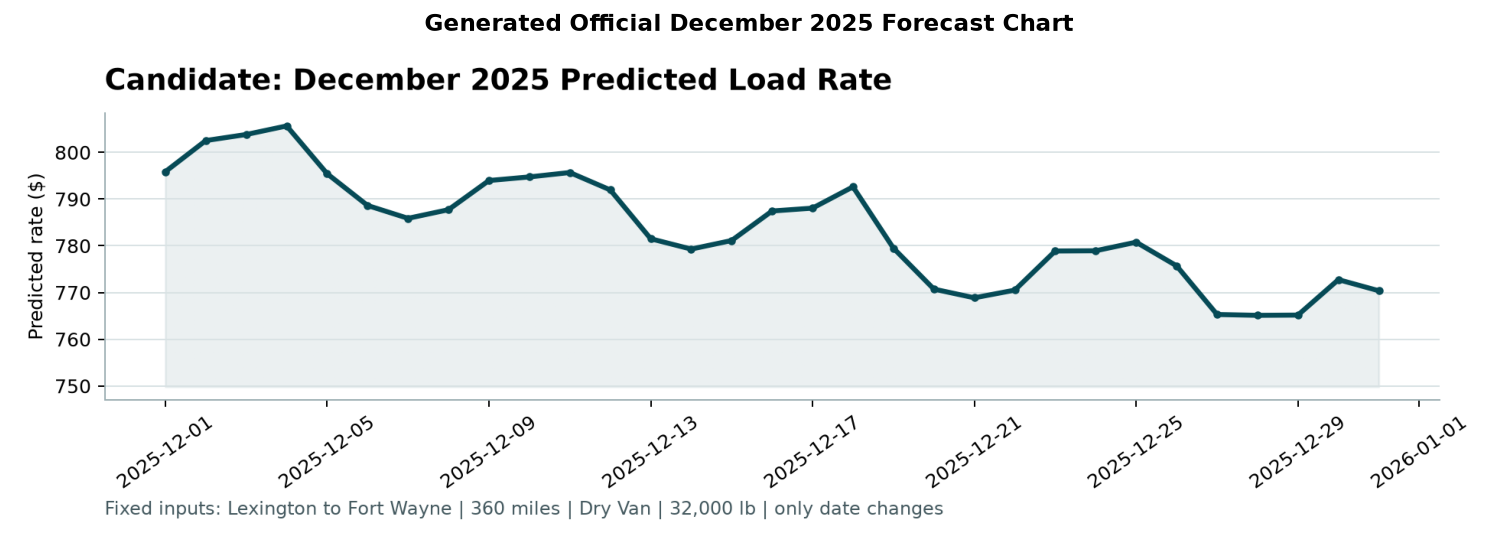

In [12]:
import subprocess
import sys

# Run official score.py validation
res = subprocess.run(
    [sys.executable, str(ROOT / "score.py"),
     "--predictions", str(ROOT / "validation_predictions.csv"),
     "--december-predictions", str(ROOT / "data/december_chart_inputs.csv"),
     "--output-dir", str(ROOT / "scorer_results")],
    capture_output=True, text=True, check=True
)
print("score.py output:\n" + res.stdout.strip())

# Display the generated December prediction chart
chart_path = ROOT / "scorer_results" / "candidate_december.png"
if chart_path.exists():
    img = plt.imread(str(chart_path))
    fig, ax = plt.subplots(figsize=(10.8, 4.8), dpi=140)
    ax.imshow(img)
    ax.axis('off')
    ax.set_title("Generated Official December 2025 Forecast Chart", pad=12, fontweight='bold')
    plt.tight_layout()
    plt.show()

## 11. Final Delivery Checklist & Verification

All deliverables specified in the assessment requirements are fully generated, verified, and ready:
- [x] **Repository & Source Code:** Clean, reproducible pipeline in `freight/`, `run.py`, `score.py`.
- [x] **Validation Predictions:** `validation_predictions.csv` (12,000 IDs, positive finite rates, exact template alignment).
- [x] **Fixed December Predictions:** `data/december_chart_inputs.csv` & `december_predictions.csv` (31 days).
- [x] **Comprehensive Report:** `reports/freight_rate_report.pdf` & `reports/freight_rate_report.docx` containing validation design, data split rationale, and candidate December chart.
- [x] **Video Narration Script:** `reports/video_script.md` timed at 2–3 minutes covering all five required prompts.
- [x] **Delivery Verification Script:** `python -m scripts.verify_delivery` passing 100%.